# Trajectory inference with Palantir and PAGA

*Python port of the R vignette [Trajectory inference with Palantir and PAGA](https://gregorlueg.github.io/bixverse/articles/trajectory_inference.html). Original author: Gregor Lueg.*

## Intro

Two trajectory methods live in `bixverse`, both operating on the kNN graph you
already built with `bv.graph.find_neighbours()`.

**Palantir** ([Setty et al.,
2019](https://doi.org/10.1038/s41587-019-0068-4)) models differentiation as a
Markov chain over a multiscale diffusion map of the cells. Out come a pseudotime
per cell, the probability of each cell reaching each terminal state, and the
differentiation entropy derived from those probabilities. It needs a start cell
and, optionally, the terminal states.

**PAGA** ([Wolf et al., 2019](https://doi.org/10.1186/s13059-019-1663-x))
abstracts the cell-level graph into a cluster-level one, where the edge weight
between two clusters measures how much more connected they are than a random
null model expects. Its maximum spanning forest is the backbone people usually
draw. PAGA needs a clustering and nothing else.

The data set is the one from the [Palantir sample
notebook](https://github.com/dpeerlab/Palantir/blob/master/notebooks/Palantir_sample_notebook.ipynb):
4142 human CD34+ bone marrow cells across 16106 genes, already filtered. Three
lineages come out of it, erythroid, monocyte and dendritic cell, all seeded from
a haematopoietic stem cell pool.

The two supporting pieces from that notebook are here too. **MAGIC** ([van
Dijk et al., 2018](https://doi.org/10.1016/j.cell.2018.05.061)) smooths counts
over the same kNN graph, which is what makes the marker plots readable.
**Gene trends** fit a landmark Gaussian process per branch, the Mellon-based
estimator the reference uses rather than the legacy GAM. Both are restricted to
a gene subset in `bixverse`, for reasons spelled out where they come up.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import MinQualityParams, NeighboursParams, PalantirParams

## Loading the data

In [2]:
marrow_path = bv.io.download_marrow_cd34()

bv.io.read_h5ad_metadata(marrow_path)["dims"]

(4142, 16106)

The `var` index of this file is the gene symbol, so no Ensembl mapping is
needed. Cell barcodes look like `Run4_120703408880541`, which matters later:
the start cell and the terminal states from the reference notebook are given as
barcodes.

In [3]:
tempdir_marrow = tempfile.TemporaryDirectory()

sc = bv.io.load_h5ad(
    Path(tempdir_marrow.name) / "marrow",
    marrow_path,
    qc=MinQualityParams(
        min_unique_genes=100,
        min_lib_size=250,
        min_cells=10,
        target_size=10000.0,
    ),
)

sc

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading CSR matrix structure (shape: 4_142 x 16_106 )...
First pass - gene expression statistics:
  Processed 100% of chunks (1/1)
  Gene expression stats: min = 1 | max = 4_142 | avg = 561 cells per gene
First pass done: 33.98ms
  Genes passing filter: 14_502 / 16_106
Second pass - cell statistics:
  Processed 100% of chunks (1/1)
  Cell stats: genes per cell: min = 769 | max = 4_712
  Cell stats: library size: min = 1832.0 | max = 33497.0
Second pass done: 70.28ms
  Cells passing filter: 4_142 / 4_142
Step 2/3: QC Results:
  Genes passing QC: 14_502 / 16_106
  Cells passing QC: 4_142 / 4_142
Step 3/3: Writing cells to CSR format...
  Processing 4_142 cells in batches of 1_000...
  Processed 1_000 / 4_142 cells
  Processed 2_000 / 4_142 cells
  Processed 3_000 / 4_142 cells
  Processed 4_000 / 4_142 cells
  Processed 4_142 / 4_142 cells
Converting the cell-based data into the gene-based format.
  Writing complete in 69

  Counted 9_031_129 non-zeros over 14_502 genes in 3.92ms; converting in 1 phase(s).


  Phase 1/1: genes 0-14502, scatter 12.87ms, compress + write 86.77ms
  Conversion into gene-friendly format done: 105.11ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpqrvttbmq/marrow',
  cells=4142 (kept 4142), genes=14502,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

The data ships pre-filtered, so there is no QC step here. On your own data you
would run `bv.qc.run_cell_qc()` and `sc.set_cells_to_keep()` first, as in the
[PBMC vignette](pbmc_single_cell.ipynb).

## Feature selection, PCA and neighbours

Standard pipeline. The one choice worth spelling out is `k = 30` on the kNN
graph: Palantir builds its diffusion kernel from whatever graph is stored on the
object, and 30 neighbours is what the reference uses. The distance metric has to
be euclidean, since the diffusion kernel is a Gaussian over a metric distance
and cosine is not one.

`pruning` does not have to move with `k`. A Jaccard threshold `p` asks two
cells to share a fraction `2p / (1 + p)` of their neighbourhoods, whatever `k`
is, so the default `1/16` keeps the same ~12% at `k = 30` as at `k = 15`.

In [4]:
bv.pp.find_hvg(sc, hvg_no=1500)

bv.pp.calculate_pca(sc, no_pcs=30)

bv.graph.find_neighbours(
    sc,
    neighbours_params=NeighboursParams(k=30, ann_dist="euclidean"),
)

bv.graph.find_clusters(sc, res=0.7, name="leiden_clusters")

bv.embed.umap(sc)

HVG (VST): 14_502 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 16.13ms
HVG (VST): Fitted Loess in 843.33µs
HVG (VST): Standardised variance in 249.25µs (32 gene(s) re-read for the clip)
HVG (VST): Total run time -> 17.28ms
Using sparse SVD solving on scaled data on 1500 HVG.


Sparse PCA: Loaded in data in 10.69ms
Sparse PCA: finished the data preparations in 1.55ms


Sparse PCA: finished calculations in 370.48ms
Sparse PCA: total run time -> 382.83ms
Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 24.16ms
Generated KmKnn index: 24.58ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 22.91ms
Queried KmKnn index: 22.97ms
Generating the snn graph.


Added 1 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 49.12ms


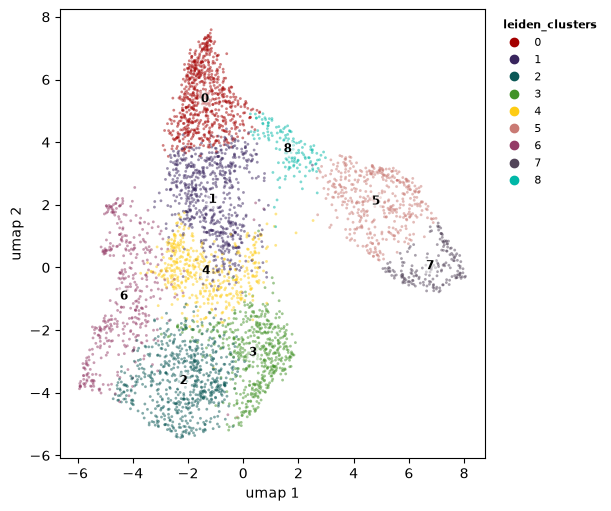

In [5]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "leiden_clusters",
    label_by="leiden_clusters",
    discrete=True,
)
plt.show()

The four markers the reference notebook uses: `CD34` for the stem pool, `MPO`
for the myeloid arm, `GATA1` for the erythroid one and `IRF8` for the dendritic
one. Raw, these are sparse and speckled, but the gradients are visible.

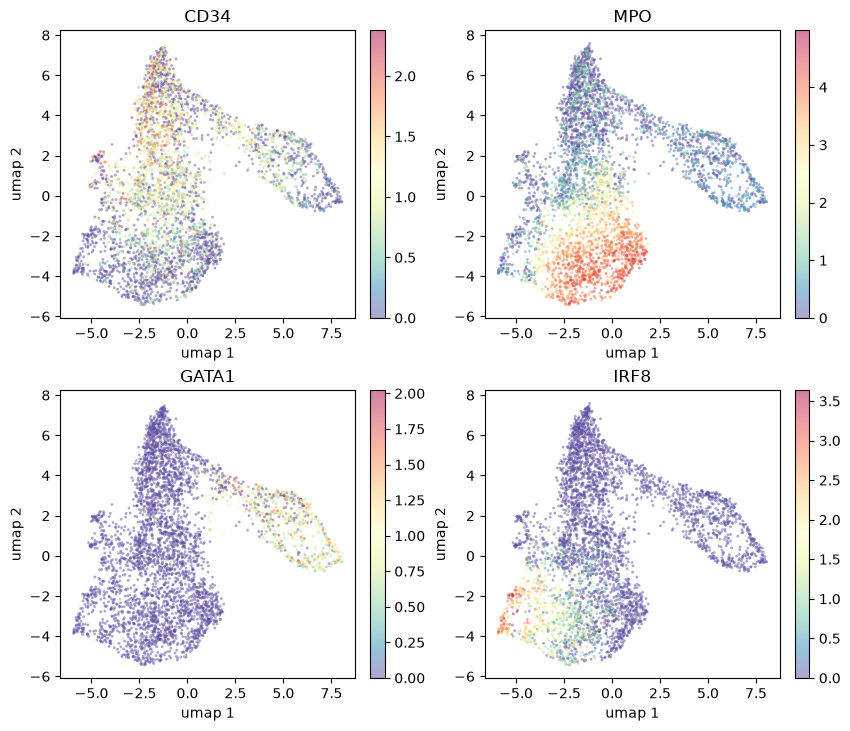

In [6]:
markers = ["CD34", "MPO", "GATA1", "IRF8"]

bv.pl.feature_plot(sc, markers, "umap", palette="spectral")
plt.show()

## MAGIC imputation

MAGIC builds a row-stochastic operator over the kNN graph and applies it three
times, so every cell becomes a weighted average of its neighbourhood. It is the
same adaptive-bandwidth kernel Palantir uses for its diffusion map, so the two
agree on what a neighbourhood is.

`bv.pp.run_magic()` writes the result onto the object as a cached layer,
`sc.cache.magic`. It takes a gene list rather than doing everything, and that
is deliberate: the output is dense, and the whole point of the on-disk store is
not holding a dense cells-by-genes matrix. Pick the genes you want to look at.

In [7]:
bv.pp.run_magic(sc, markers)

magic = sc.cache.magic

print(f"{magic.data.shape[0]} cells x {magic.data.shape[1]} genes: {magic.features}")

Running MAGIC over the rna kNN graph (4142 cells, 4 genes, 3 steps).


MAGIC: imputed 4 genes across 4142 cells in 635.04µs
4142 cells x 4 genes: ['CD34' 'MPO' 'GATA1' 'IRF8']


Every extractor takes `layer="magic"`, and `feature_plot()` passes it straight
through.

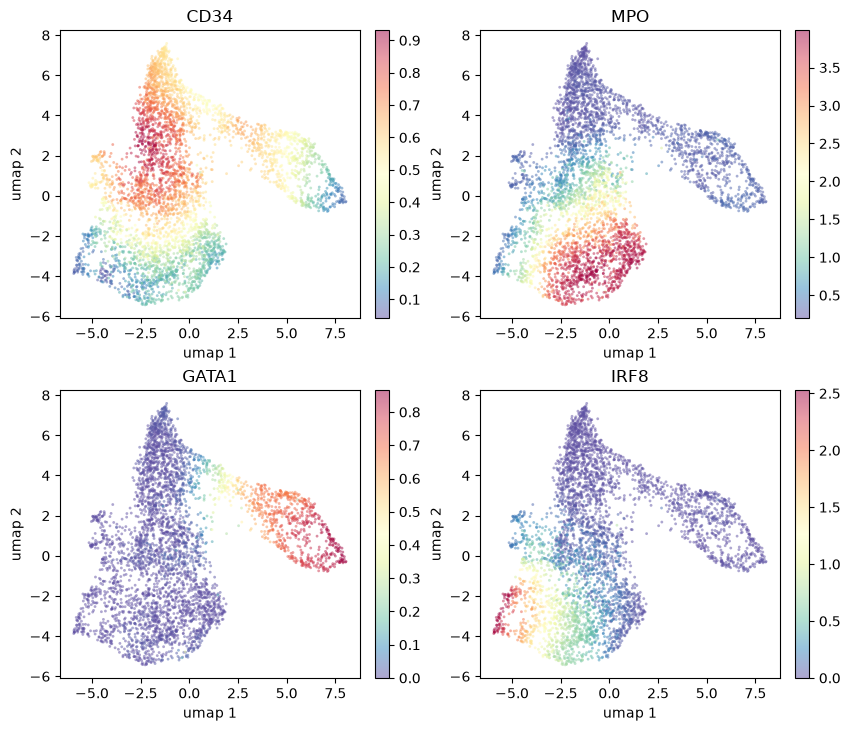

In [8]:
bv.pl.feature_plot(sc, markers, "umap", palette="spectral", layer="magic")
plt.show()

That is the picture people know from the paper, and it is worth being clear
about what produced it. Neighbourhoods overlap, so smoothing over them makes
nearby cells resemble each other in every gene at once. Gene-gene correlation
after imputation is inflated, badly, and the inflation is a property of the
graph rather than of the biology. Do not feed these values into Hotspot,
SCENIC, differential correlation or CoReMo: those methods measure exactly the
quantity MAGIC manufactures, and they will report the graph back to you as a
finding. `extract_dot_plot_data()` has no `layer` argument for the same reason.

The layer is tracked like every other cached artefact, so it goes stale when
the graph under it moves.

In [9]:
sc.cache_status()

artefact,stamped,stale,reason,id,parents
str,bool,bool,str,str,list[str]
"""pca""",true,false,null,"""6358d10a490c4485""",[]
"""umap""",true,false,null,"""00d1eb5d845d4b92""","[""6358d10a490c4485"", ""b607da4dca4d4da8""]"
"""knn""",true,false,null,"""b607da4dca4d4da8""","[""6358d10a490c4485""]"
"""connectivities""",true,false,null,"""64bf75fd201a47d2""","[""b607da4dca4d4da8""]"
"""magic""",true,false,null,"""1fa6cee4e2434b46""","[""b607da4dca4d4da8""]"


## PAGA

PAGA is the cheap one, so start there. It reads the kNN indices and a
clustering, ignores the distances entirely, and gives back a
clusters-by-clusters graph.

In [10]:
paga_res = bv.traj.run_paga(sc, "leiden_clusters")

paga_res

Running PAGA over the rna kNN graph (4142 cells, 9 clusters).


PagaRes(
  n_clusters=9,
  n_cells=4142,
  modality='rna',
  cluster_col='leiden_clusters',
  n_edges=31,
  n_tree_edges=8,
)

`connectivities` is the full abstracted graph, `connectivities_tree` its
maximum spanning forest. Both are symmetric dense arrays in the order of
`paga_res.clusters`, with a zero diagonal.

In [11]:
paga_res.sizes

cluster,n_cells
str,u32
"""0""",691
"""1""",674
"""2""",634
"""3""",523
"""4""",449
"""5""",429
"""6""",413
"""7""",186
"""8""",143


In [12]:
# show every cluster column
pl.Config.set_tbl_cols(-1)

pl.DataFrame(
    np.round(paga_res.connectivities, 3), schema=list(paga_res.clusters)
).insert_column(0, pl.Series("cluster", paga_res.clusters))

cluster,0,1,2,3,4,5,6,7,8
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""0""",0.0,0.474,0.001,0.0,0.001,0.002,0.026,0.001,0.395
"""1""",0.474,0.0,0.028,0.07,0.599,0.003,0.196,0.0,0.328
"""2""",0.001,0.028,0.0,0.445,0.121,0.003,0.329,0.001,0.005
"""3""",0.0,0.07,0.445,0.0,0.431,0.004,0.044,0.0,0.006
"""4""",0.001,0.599,0.121,0.431,0.0,0.015,0.258,0.0,0.077
"""5""",0.002,0.003,0.003,0.004,0.015,0.0,0.004,0.701,0.533
"""6""",0.026,0.196,0.329,0.044,0.258,0.004,0.0,0.0,0.004
"""7""",0.001,0.0,0.001,0.0,0.0,0.701,0.0,0.0,0.0
"""8""",0.395,0.328,0.005,0.006,0.077,0.533,0.004,0.0,0.0


`paga_plot()` puts every cluster at the centroid of its cells in an embedding
and draws the graph over them. A free layout of the abstracted graph would put
the nodes somewhere arbitrary, which you then have to relate back to the UMAP
by eye.

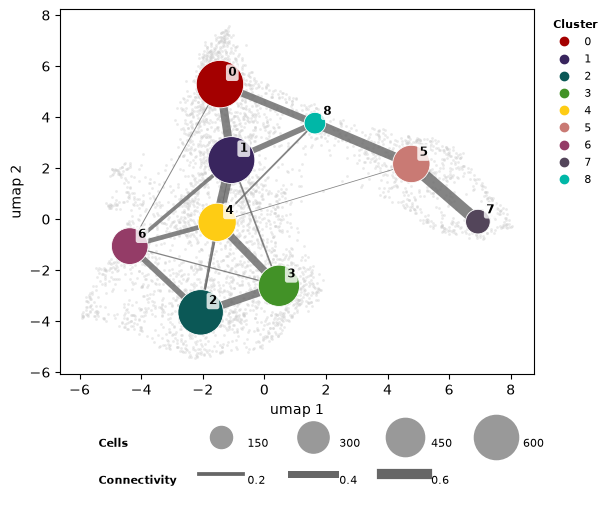

In [13]:
bv.pl.paga_plot(sc, paga_res, embedding="umap")
plt.show()

Edge thresholding is not optional. The abstracted graph is close to complete on
real data, so at `threshold=0` you get a hairball. `tree_only=True` is the
shortcut to the backbone, and it is the readable one on anything above a
handful of clusters.

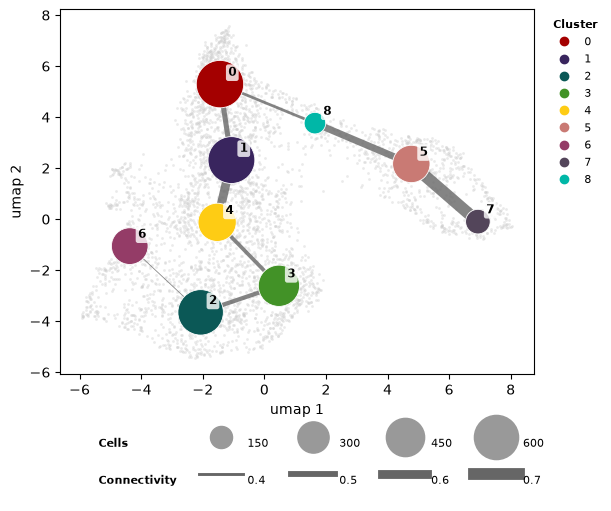

In [14]:
bv.pl.paga_plot(sc, paga_res, embedding="umap", tree_only=True)
plt.show()

If you want the node and edge tables to draw yourself, they come out of
`bv.pl.extract_paga_plot_data()`, which is what the plot is built on.

In [15]:
paga_data = bv.pl.extract_paga_plot_data(sc, paga_res, tree_only=True)

paga_data.edges.head()

from,to,weight,x,y,xend,yend
str,str,f64,f64,f64,f64,f64
"""0""","""1""",0.473612,-1.44101,5.295949,-1.068905,2.318085
"""0""","""8""",0.395327,-1.44101,5.295949,1.642429,3.765311
"""1""","""4""",0.599112,-1.068905,2.318085,-1.53302,-0.123007
"""2""","""3""",0.445219,-2.068866,-3.65324,0.473801,-2.61107
"""2""","""6""",0.329213,-2.068866,-3.65324,-4.371003,-1.056478


## Palantir

The start cell and the three terminal states come straight from the reference
notebook. The start cell was picked there for high `CD34` expression; the
terminal states are one cell each in the dendritic, monocyte and erythroid tips.

In [16]:
early_cell = "Run5_164698952452459"

terminal_states = {
    "DC": "Run5_131097901611291",
    "Mono": "Run5_134936662236454",
    "Ery": "Run4_200562869397916",
}

`knn=30` is the neighbour count for the geodesic graph Palantir builds on the
multiscale space, a different knob from the `k` of the input kNN graph.
`num_waypoints` stays at its 1200 default; the reference notebook drops it to
500.

Two things do not mirror the reference, and both change what you get.

`use_early_cell_as_start` is `True`, so the early cell you name is the one that
gets used. The reference snaps it to the nearest boundary cell of the diffusion
map instead, and that candidate set is small, at most two cells per multiscale
component. On a branching manifold the snap will cheerfully move a root cell
onto a branch tip and run the whole trajectory backwards.

`n_eigs` is pinned at 10, leaving nine multiscale components. Left at `None`
the count comes from the largest eigengap, and nothing stops that from landing
on 3, i.e. two components. Two components cannot resolve a three-way branch: the erythroid arm
separates fine but the monocyte and dendritic fate probabilities end up
correlated, their branch masks collapse onto each other, and the gene trends
for those two lineages come out nearly identical. There is a section on that
below.

In [17]:
palantir_res = bv.traj.run_palantir(
    sc,
    early_cell,
    terminal_states=terminal_states,
    palantir_params=PalantirParams(n_eigs=10, knn=30),
    seed=42,
)

palantir_res

Running Palantir over the rna kNN graph (4142 cells).


Building the multiscale diffusion space...
Sampled 997 waypoints; start cell is 2693.
Computing geodesic distances from 997 waypoints...
Refining pseudotime (cap 25 iterations)...
Constructing the waypoint Markov chain...
Solving for 3 terminal states...


PalantirRes(
  n_cells=4142,
  n_terminal_states=3,
  modality='rna',
  start_cell='Run5_164698952452459',
  n_waypoints=997,
  converged=True,
  iterations=2,
  repair_edges=0,
  stranded_waypoints=0,
  eigen_converged=True,
)

Two things to watch in that print out. Repair edges above zero means the kNN
graph was disconnected and had to be bridged, which usually means `k` is too
small for the data. A note about the diffusion eigensolve not converging means
the embedding is under-resolved, and every distance taken on it is suspect;
raise `lanczos_max_restarts` in `PalantirParams` before believing anything
downstream.

### Results back onto the object

`PalantirRes` is keyed by cell id, not position, so join it onto obs on
`cell_id` rather than assuming the two are in the same order.

In [18]:
obs_cells = sc.obs(cols=["cell_idx", "cell_id"], filtered=True)

sc.add_obs(
    obs_cells.join(palantir_res.pseudotime, on="cell_id", how="left").select(
        "cell_idx",
        pl.col("pseudotime").alias("palantir_pseudotime"),
        pl.col("entropy").alias("palantir_entropy"),
    )
)

The fate probability frame has one column per terminal state. Because
`terminal_states` was a dict, its keys are already the column names, so all
that is left is the dominant fate per cell.

In [19]:
lineages = palantir_res.branches

fate_probs = obs_cells.join(palantir_res.branch_probs, on="cell_id", how="left")

prob_mat = fate_probs.select(lineages).to_numpy()

sc.add_obs(
    fate_probs.select(
        "cell_idx",
        *[pl.col(lineage).alias(f"fate_{lineage}") for lineage in lineages],
    ).with_columns(
        pl.Series(
            "palantir_branch", np.asarray(lineages)[prob_mat.argmax(axis=1)]
        ).cast(pl.Enum(lineages))
    )
)

fate_probs.select("cell_id", pl.col(lineages).round(3)).head()

cell_id,Ery,DC,Mono
str,f32,f32,f32
"""Run4_120703408880541""",0.559,0.088,0.353
"""Run4_120703409056541""",0.215,0.157,0.628
"""Run4_120703409580963""",0.055,0.139,0.805
"""Run4_120703423990708""",0.016,0.035,0.95
"""Run4_120703436876077""",0.209,0.158,0.633


Rows do not necessarily sum to one. Fate probabilities below
`branch_prob_threshold` (0.01 by default) are zeroed without renormalisation,
and cells whose waypoint weight sits on a stranded waypoint lose that mass
entirely.

### Pseudotime and entropy

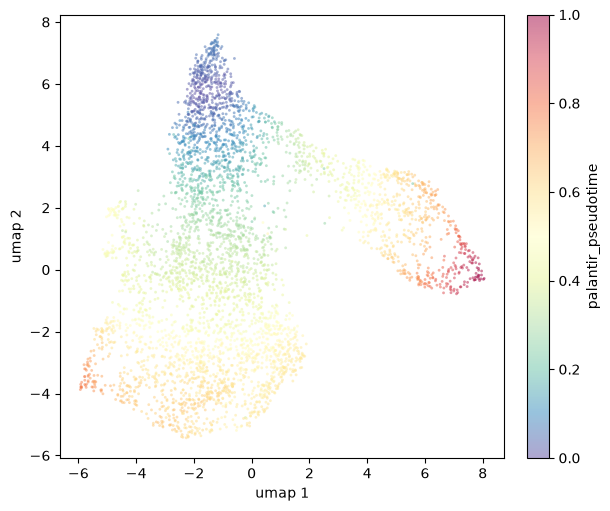

In [20]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "palantir_pseudotime",
    palette="spectral",
    discrete=False,
)
plt.show()

The same quantity on the abstracted graph is worth a look, because it is the
cheapest check that the two methods agree. PAGA knows nothing about pseudotime,
so if its backbone and the pseudotime gradient point in different directions,
one of them is wrong.

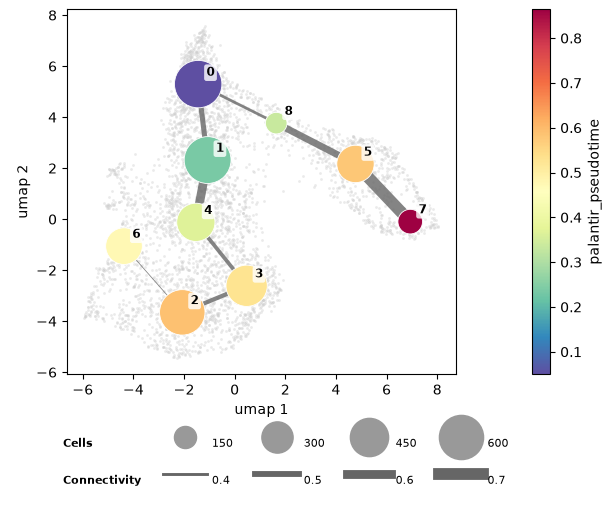

In [21]:
bv.pl.paga_plot(
    sc,
    paga_res,
    embedding="umap",
    node_colour_by="palantir_pseudotime",
    palette="spectral",
    tree_only=True,
)
plt.show()

Entropy is high where a cell still has several fates open to it and drops to
zero once it commits. Three equally likely fates give `log(3)`, the ceiling.
Here the stem pool sits below it, because the monocyte fate already carries
more than its third of the probability there.

In [22]:
print(
    f"max entropy {palantir_res.pseudotime['entropy'].max():.3f}, "
    f"log(3) = {np.log(3):.3f}"
)

max entropy 0.973, log(3) = 1.099


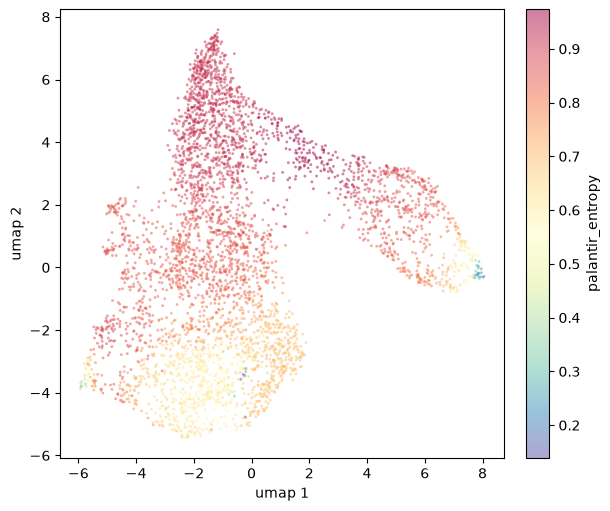

In [23]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "palantir_entropy",
    palette="spectral",
    discrete=False,
)
plt.show()

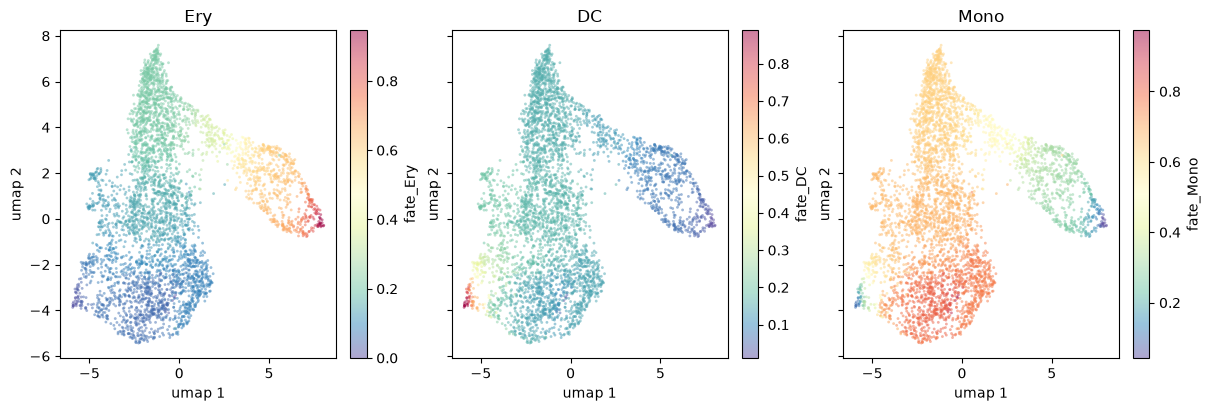

In [24]:
fig, axes = plt.subplots(
    1, len(lineages), figsize=(12, 4), layout="constrained", sharey=True
)

for ax, lineage in zip(axes, lineages, strict=True):
    bv.pl.embedding_plot(
        sc,
        "umap",
        f"fate_{lineage}",
        palette="spectral",
        discrete=False,
        ax=ax,
    )
    ax.set_title(lineage)

plt.show()

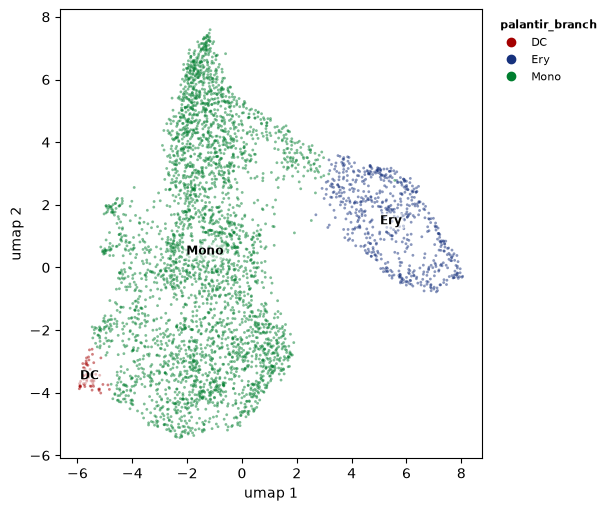

In [25]:
bv.pl.embedding_plot(
    sc,
    "umap",
    "palantir_branch",
    label_by="palantir_branch",
    discrete=True,
)
plt.show()

### Letting Palantir find the terminal states

Drop `terminal_states` and they get detected from the waypoint Markov chain
instead. Handy when you have no prior, but treat the result as a starting point
rather than an answer: the detection reads extremes of the multiscale space, and
on data sets this size those are not always well determined.

In [26]:
palantir_auto = bv.traj.run_palantir(
    sc,
    early_cell,
    palantir_params=PalantirParams(n_eigs=10, knn=30, use_early_cell_as_start=True),
    seed=42,
)

palantir_auto.terminal_states

Running Palantir over the rna kNN graph (4142 cells).


Building the multiscale diffusion space...
Sampled 994 waypoints; start cell is 2693.
Computing geodesic distances from 994 waypoints...
Refining pseudotime (cap 25 iterations)...
Constructing the waypoint Markov chain...


Solving for 2 terminal states...


{'Run5_205922701598003': 'Run5_205922701598003',
 'Run5_235070783670620': 'Run5_235070783670620'}

Where did they land relative to the supplied ones?

In [27]:
pl.DataFrame({"cell_id": list(palantir_auto.terminal_states.values())}).join(
    sc.obs(cols=["cell_id", "palantir_branch", "palantir_pseudotime"], filtered=True),
    on="cell_id",
    how="left",
    maintain_order="left",
).with_columns(pl.col("palantir_pseudotime").round(3))

cell_id,palantir_branch,palantir_pseudotime
str,enum,f32
"""Run5_205922701598003""","""Mono""",0.075
"""Run5_235070783670620""","""Mono""",0.576


Two instead of three, both on the monocyte arm, and one of them sits at a
pseudotime of 0.075, right next to the root. Neither the dendritic nor the
erythroid tip turns up. Starting point, not answer.

## Gene trends

`bv.traj.run_gene_trends()` does two things. First it assigns cells to
branches: for each fate, the probability threshold is an expanding quantile
over the pseudotime-sorted cells, made monotone with a cumulative maximum, so a
fate's bar can only rise as differentiation proceeds. Then it fits a landmark
Gaussian process with a Matern-5/2 kernel per branch, on a 500 point pseudotime
grid.

In [28]:
trends = bv.traj.run_gene_trends(sc, palantir_res, features=markers)

trends

Fitting gene trends over 3 branches (4142 cells, 4 genes, normalised counts).


GeneTrendsRes(
  branches=['Ery', 'DC', 'Mono'],
  n_genes=4,
  resolution=500,
  cells_per_branch={'Ery': 1380, 'DC': 1536, 'Mono': 1940},
  source='norm',
  length_scale=1.0,
  sigma=1.0,
  extra_jitter=False,
)

`trends.trends` is a long polars frame with `branch`, `pseudotime`, `gene` and
`expression`, one panel per gene away from a facet.

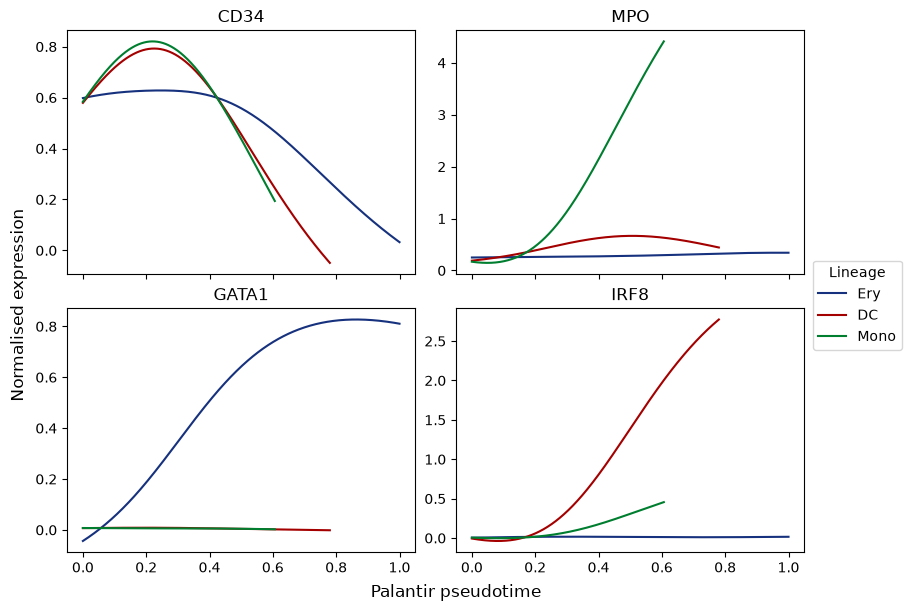

In [29]:
# the embedding plots colour the branches in sorted order, so match them
colours = dict(
    zip(
        sorted(lineages),
        bv.pl.bx_colors("main", n=len(lineages)),
        strict=True,
    )
)

fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout="constrained", sharex=True)

for ax, gene in zip(axes.flat, markers, strict=True):
    for branch in trends.branches:
        df = trends.trends.filter(
            (pl.col("gene") == gene) & (pl.col("branch") == branch)
        )
        ax.plot(
            df["pseudotime"],
            df["expression"],
            color=colours[branch],
            lw=1.5,
            label=branch,
        )
    ax.set_title(gene)

fig.supxlabel("Palantir pseudotime")
fig.supylabel("Normalised expression")
fig.legend(
    *axes.flat[0].get_legend_handles_labels(),
    title="Lineage",
    loc="outside right center",
)
plt.show()

`CD34` falls away from the root, `GATA1` climbs on the erythroid arm, `MPO` on
the monocyte one, `IRF8` on the dendritic one. Set `use_magic=True` to fit the
imputed layer instead, which is what the reference notebook does. Note that the
GP already smooths over pseudotime, so imputing first smooths twice.

`branch_cells` carries the selection itself, which is the branch cell set the
reference notebook plots.

In [30]:
{branch: len(cells) for branch, cells in trends.branch_cells.items()}

{'Ery': 1380, 'DC': 1536, 'Mono': 1940}

The same trick works with any per-cell quantity. A smoothed curve through the
entropy column watches commitment happen along the trajectory. There is no
loess in numpy, so a running median over the pseudotime-sorted cells of each
dominant fate stands in for it.

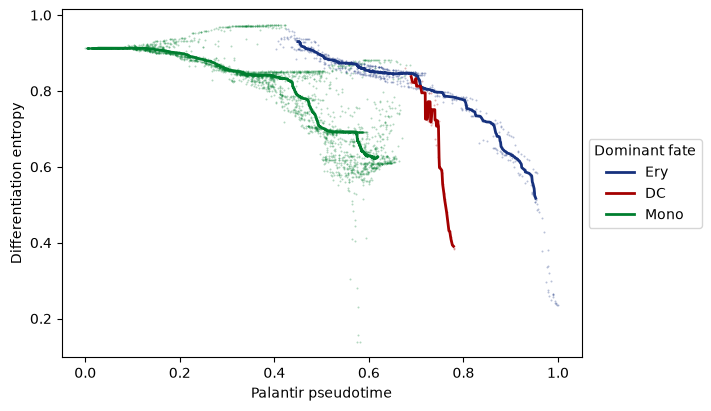

In [31]:
obs = sc.obs(
    cols=["palantir_pseudotime", "palantir_entropy", "palantir_branch"],
    filtered=True,
).sort("palantir_pseudotime")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")

for lineage in lineages:
    df = obs.filter(pl.col("palantir_branch") == lineage)
    ax.scatter(
        df["palantir_pseudotime"],
        df["palantir_entropy"],
        s=2,
        alpha=0.3,
        color=colours[lineage],
        linewidths=0,
    )
    window = max(df.height // 10, 1)
    smooth = df.select(
        "palantir_pseudotime",
        pl.col("palantir_entropy").rolling_median(window, center=True),
    )
    ax.plot(
        smooth["palantir_pseudotime"],
        smooth["palantir_entropy"],
        color=colours[lineage],
        lw=2,
        label=lineage,
    )

ax.set_xlabel("Palantir pseudotime")
ax.set_ylabel("Differentiation entropy")
ax.legend(title="Dominant fate", loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

## Where this can go wrong

Palantir has more moving parts than most methods in this package, and several of
them fail quietly rather than loudly. In rough order of how often they bite:

- **Pruning too hard.** Upstream of Palantir entirely. It costs you clusters,
  not pseudotime, but a one-cell cluster then walks into PAGA and comes back
  out as a fat edge into a dot, because the null model has almost no possible
  edges to normalise against. `rescue=True` (the default) reconnects the
  small components pruning cuts off, so this mainly bites with it switched off.
- **The start cell.** Covered above. Set `use_early_cell_as_start=False` to
  get the reference behaviour and it can move your root onto a branch tip. If
  pseudotime comes back anti-correlated with what you expect, check
  `start_cell` on the result object first. Note that pseudotime is not pinned
  to zero at the start cell either: the refinement can put the minimum on a
  neighbour, and a start cell far from zero means it disagreed with your
  anchor.
- **`eigen_converged` is `False`.** The diffusion eigensolve ran out of
  restarts, so the multiscale embedding is under-resolved. Everything
  downstream converges happily on noise, which is exactly why this is reported
  in `run_info`. Raise `lanczos_max_restarts`.
- **`repair_edges > 0`.** The kNN graph was disconnected and Palantir bridged
  it to carry on. Raise `k` on `find_neighbours()` rather than living with the
  bridges.
- **`stranded_waypoints > 0`.** Waypoints from which no terminal state is
  reachable. Their cells lose fate probability mass, so rows sum below one. A
  large count means the pseudotime-directed pruning cut too hard.
- **`n_eigs`.** The one that bites hardest, and it is silent. Left at `None`
  the eigenvector count comes from the largest eigengap, and if that lands
  on 3 it leaves two multiscale components for a three-way branch. Nothing
  errors. What happens instead is that two of the three fates stop separating:
  their probabilities correlate, the branch selection hands the two branches
  almost the same cells, and their gene trends come out on top of each other.
  If two lineages give you the same curve, count the components before you
  blame the estimator. The check is below.
- **Branch masks are permissive by design.** Even at a sensible `n_eigs`, a
  cell belongs to a branch when its fate probability is near the top of what
  has been seen up to its pseudotime, so the uncommitted trunk sits in every
  branch at once. That is the reference's logic and it is the right one, but it
  means two branches only diverge where their late cells differ. Check
  `branch_cells` overlap before reading much into two curves that hug.
- **The gene trend defaults are prior-dominated.** Pseudotime is min-max
  scaled to `[0, 1]`, so the reference's `length_scale = 1` spans the entire
  domain and its `sigma = 1` sits at roughly the signal scale of log-normalised
  expression. Almost any gene resolves into a smooth monotone or single-peaked
  curve. That is a presentation choice, not inference. Shorten `length_scale`
  in `GeneTrendsParams` before believing a bump.
- **Double smoothing.** MAGIC averages over the graph and the GP averages over
  pseudotime. Running both is defensible for a figure and rarely necessary for
  the trend itself. If a feature only shows up with `use_magic=True`, that is
  worth knowing about.
- **A stale imputed layer.** The layer is stamped against the kNN graph it came
  from, so `sc.cache_status()` flags it once the graph or the cell filter
  moves. `run_gene_trends(use_magic=True)` refuses to fit a stale one.

Counting the components: the multiscale frame has one column per component.
The run below leaves `n_eigs` at the eigengap default and compares the
monocyte and dendritic branch masks against the pinned run.

In [32]:
palantir_gap = bv.traj.run_palantir(
    sc,
    early_cell,
    terminal_states=terminal_states,
    palantir_params=PalantirParams(knn=30),
    seed=42,
)

rows = []
for label, res in [("eigengap", palantir_gap), ("n_eigs = 10", palantir_res)]:
    branch_cells = bv.traj.run_gene_trends(sc, res, features=["CD34"]).branch_cells
    mono, dc = set(branch_cells["Mono"]), set(branch_cells["DC"])
    rows.append(
        {
            "n_eigs": label,
            "components": res.multiscale.width - 1,
            "mono_cells": len(mono),
            "dc_cells": len(dc),
            "shared": len(mono & dc),
            "mono_only": len(mono - dc),
        }
    )

pl.DataFrame(rows)

Running Palantir over the rna kNN graph (4142 cells).


Building the multiscale diffusion space...
Sampled 1071 waypoints; start cell is 2693.
Computing geodesic distances from 1071 waypoints...


Refining pseudotime (cap 25 iterations)...
Constructing the waypoint Markov chain...
Solving for 3 terminal states...
Fitting gene trends over 3 branches (4142 cells, 1 genes, normalised counts).


Fitting gene trends over 3 branches (4142 cells, 1 genes, normalised counts).


n_eigs,components,mono_cells,dc_cells,shared,mono_only
str,i64,i64,i64,i64,i64
"""eigengap""",5,2139,1998,1377,762
"""n_eigs = 10""",9,1940,1536,1118,822


On this run the eigengap keeps five components, enough for the three fates to
separate, and the overlap barely moves against the pinned run. The eigengap
hangs off the kNN graph though, so it moves with `k`, the HVGs and the PCA.
Pinning `n_eigs` takes it out of the equation.

## Clean up

In [33]:
tempdir_marrow.cleanup()